In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv('/content/heart.csv')
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
df.shape

(303, 14)

In [ ]:
#missing values
df.isnull().sum()

,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


In [ ]:
#duplicate values
df.duplicated().sum()

np.int64(1)

In [ ]:
#to remove the duplicate values
df = df.drop_duplicates()

In [ ]:
df.shape

(302, 14)

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
#inconsistent values check
categorical_columns = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal', 'target']

for col in categorical_columns:
    print(col, ":", sorted(df[col].unique()))

sex : [np.int64(0), np.int64(1)]
cp : [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
fbs : [np.int64(0), np.int64(1)]
restecg : [np.int64(0), np.int64(1), np.int64(2)]
exang : [np.int64(0), np.int64(1)]
slope : [np.int64(0), np.int64(1), np.int64(2)]
ca : [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
thal : [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
target : [np.int64(0), np.int64(1)]


In [ ]:
#final dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 302 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       302 non-null    int64  
 1   sex       302 non-null    int64  
 2   cp        302 non-null    int64  
 3   trestbps  302 non-null    int64  
 4   chol      302 non-null    int64  
 5   fbs       302 non-null    int64  
 6   restecg   302 non-null    int64  
 7   thalach   302 non-null    int64  
 8   exang     302 non-null    int64  
 9   oldpeak   302 non-null    float64
 10  slope     302 non-null    int64  
 11  ca        302 non-null    int64  
 12  thal      302 non-null    int64  
 13  target    302 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 35.4 KB


In [ ]:
#to save the final data set
df.to_csv('/content/heart_cleaned.csv', index=False)

In [ ]:
#EDA
df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,302.00000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000
mean,54.42053,0.682119,0.963576,131.602649,246.500000,0.149007,0.526490,149.569536,0.327815,1.043046,1.397351,0.718543,2.314570,0.543046
std,9.04797,0.466426,1.032044,17.563394,51.753489,0.356686,0.526027,22.903527,0.470196,1.161452,0.616274,1.006748,0.613026,0.498970
min,29.00000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.00000,0.000000,0.000000,120.000000,211.000000,0.000000,0.000000,133.250000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,55.50000,1.000000,1.000000,130.000000,240.500000,0.000000,1.000000,152.500000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.00000,1.000000,2.000000,140.000000,274.750000,0.000000,1.000000,166.000000,1.000000,1.600000,2.000000,1.000000,3.000000,1.000000
max,77.00000,1.000000,3.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


In [ ]:
print(df['target'].value_counts())

target
1    164
0    138
Name: count, dtype: int64


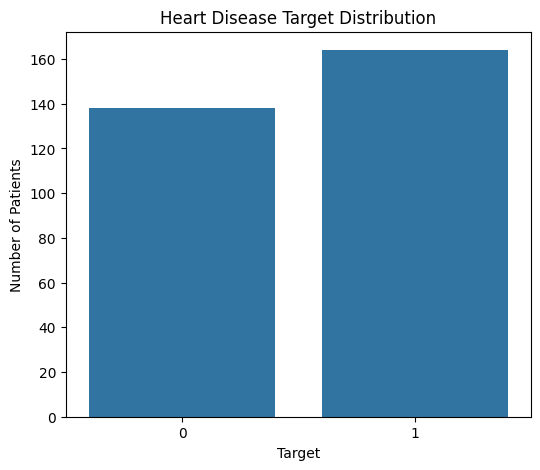

In [ ]:
plt.figure(figsize=(6,5))

sns.countplot(x='target', data=df)

plt.title('Heart Disease Target Distribution')
plt.xlabel('Target')
plt.ylabel('Number of Patients')

plt.show()

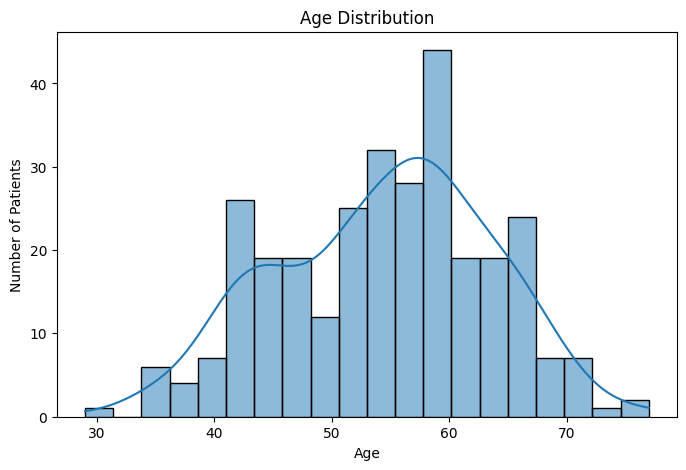

In [ ]:
#age disturbution
plt.figure(figsize=(8,5))

sns.histplot(
    df['age'],
    bins=20,
    kde=True
)

plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Number of Patients')

plt.show()

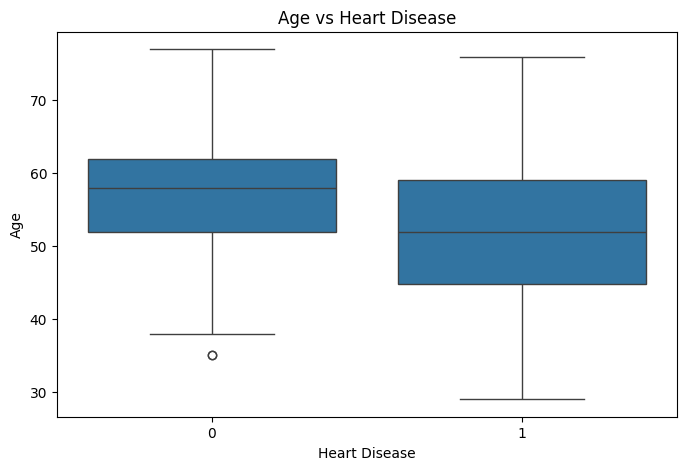

In [ ]:
#age vs heart disease
plt.figure(figsize=(8,5))

sns.boxplot(
    x='target',
    y='age',
    data=df
)

plt.title('Age vs Heart Disease')
plt.xlabel('Heart Disease')
plt.ylabel('Age')

plt.show()

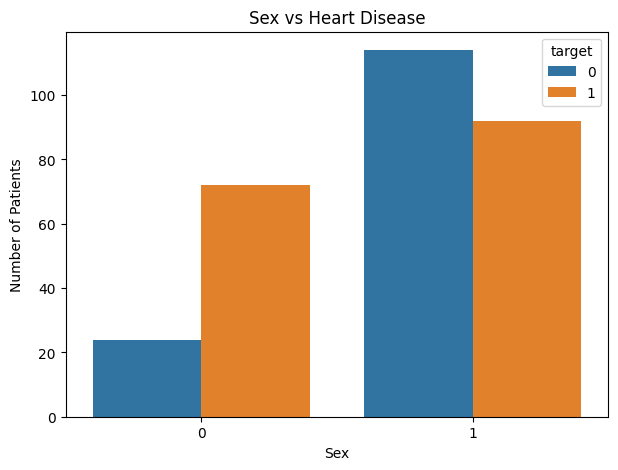

In [ ]:
#sex vs heart disease
plt.figure(figsize=(7,5))

sns.countplot(
    x='sex',
    hue='target',
    data=df
)

plt.title('Sex vs Heart Disease')
plt.xlabel('Sex')
plt.ylabel('Number of Patients')

plt.show()

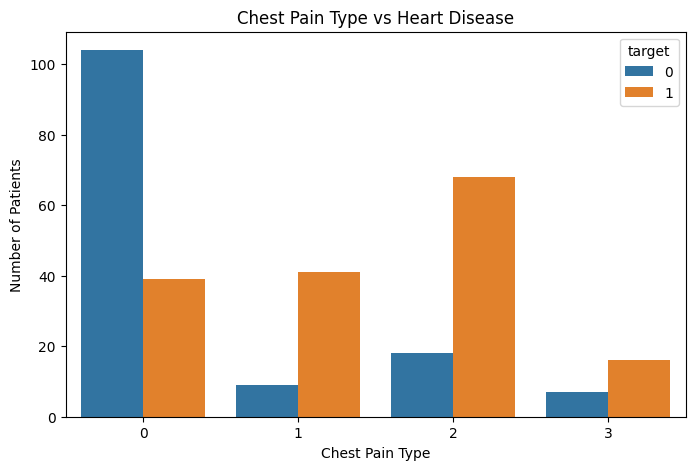

In [ ]:
#chestpain vs heart disease
plt.figure(figsize=(8,5))

sns.countplot(
    x='cp',
    hue='target',
    data=df
)

plt.title('Chest Pain Type vs Heart Disease')
plt.xlabel('Chest Pain Type')
plt.ylabel('Number of Patients')

plt.show()

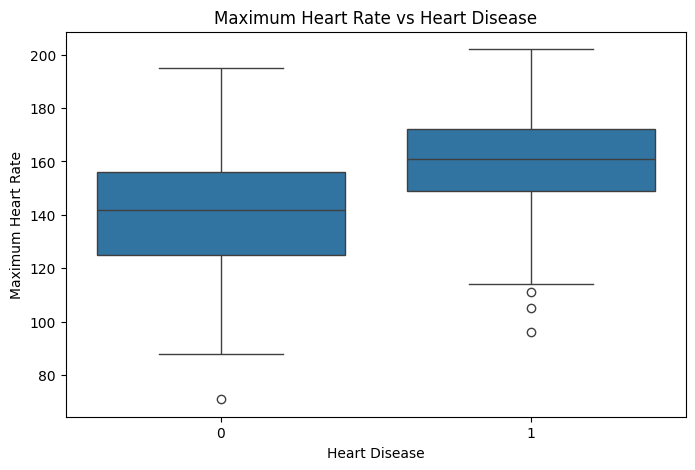

In [ ]:
#max heart rate vs heart disease
plt.figure(figsize=(8,5))

sns.boxplot(
    x='target',
    y='thalach',
    data=df
)

plt.title('Maximum Heart Rate vs Heart Disease')
plt.xlabel('Heart Disease')
plt.ylabel('Maximum Heart Rate')

plt.show()

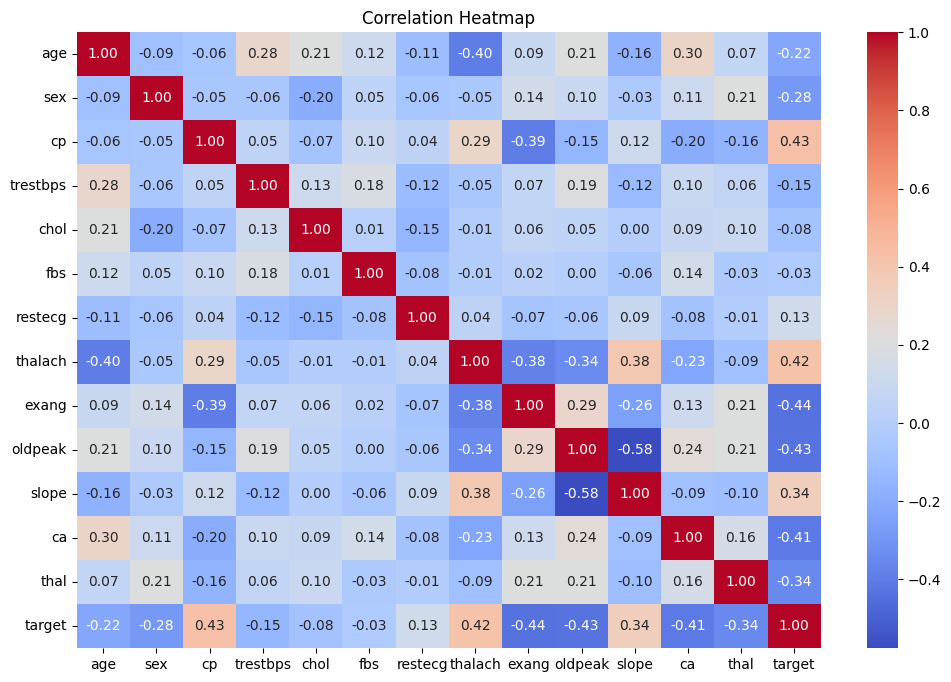

In [ ]:
#correlation heatmap
plt.figure(figsize=(12,8))

correlation = df.corr()

sns.heatmap(
    correlation,
    annot=True,
    fmt='.2f',
    cmap='coolwarm'
)

plt.title('Correlation Heatmap')

plt.show()

In [ ]:
#separate x and y
X = df.drop('target', axis=1)
y = df['target']

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   63    1   3       145   233    1        0      150      0      2.3      0   
1   37    1   2       130   250    0        1      187      0      3.5      0   
2   41    0   1       130   204    0        0      172      0      1.4      2   
3   56    1   1       120   236    0        1      178      0      0.8      2   
4   57    0   0       120   354    0        1      163      1      0.6      2   

   ca  thal  
0   0     1  
1   0     2  
2   0     2  
3   0     2  
4   0     2  

Target:
0    1
1    1
2    1
3    1
4    1
Name: target, dtype: int64


In [ ]:
#train/test split
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (241, 13)
Testing data: (61, 13)


In [ ]:
#feature scaling
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed.")

Feature scaling completed.


In [ ]:
#logistic regression
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(max_iter=1000)

logistic_model.fit(
    X_train_scaled,
    y_train
)

y_pred_lr = logistic_model.predict(
    X_test_scaled
)

print("Logistic Regression predictions:")
print(y_pred_lr)

Logistic Regression predictions:
[0 0 0 1 1 0 1 0 1 1 0 1 0 1 1 1 1 1 1 1 1 0 1 1 1 0 0 1 0 0 0 1 0 0 0 1 0
 1 1 0 1 1 1 1 0 0 1 1 1 1 1 1 1 0 1 1 1 1 0 0 1]


In [ ]:
#svm
from sklearn.svm import SVC

svm_model = SVC(kernel='rbf')

svm_model.fit(
    X_train_scaled,
    y_train
)

y_pred_svm = svm_model.predict(
    X_test_scaled
)

print("SVM predictions:")
print(y_pred_svm)

SVM predictions:
[0 0 0 1 1 0 1 0 1 1 0 1 0 1 1 1 1 1 1 1 0 0 1 1 1 0 0 1 0 1 0 1 1 0 0 1 0
 1 1 0 0 1 1 1 0 1 1 1 1 1 1 1 1 0 1 1 1 1 0 0 1]


In [ ]:
#knn
from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier(
    n_neighbors=5
)

knn_model.fit(
    X_train_scaled,
    y_train
)

y_pred_knn = knn_model.predict(
    X_test_scaled
)

print("KNN predictions:")
print(y_pred_knn)

KNN predictions:
[0 1 0 0 1 0 1 1 1 1 0 1 0 1 1 1 1 1 1 1 1 0 1 1 1 0 0 1 0 1 0 1 0 0 0 0 1
 1 1 1 0 1 1 1 0 0 1 1 1 1 0 1 1 0 1 1 1 1 0 0 1]


In [ ]:
#importing evalution matrices
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [ ]:
#evaluate logistic regression
print("LOGISTIC REGRESSION")

print("Accuracy:",
      accuracy_score(y_test, y_pred_lr))

print("Precision:",
      precision_score(y_test, y_pred_lr))

print("Recall:",
      recall_score(y_test, y_pred_lr))

print("F1 Score:",
      f1_score(y_test, y_pred_lr))

LOGISTIC REGRESSION
Accuracy: 0.7868852459016393
Precision: 0.7631578947368421
Recall: 0.8787878787878788
F1 Score: 0.8169014084507042


In [ ]:
#evaluating svm
print("SVM")

print("Accuracy:",
      accuracy_score(y_test, y_pred_svm))

print("Precision:",
      precision_score(y_test, y_pred_svm))

print("Recall:",
      recall_score(y_test, y_pred_svm))

print("F1 Score:",
      f1_score(y_test, y_pred_svm))

SVM
Accuracy: 0.8360655737704918
Precision: 0.7948717948717948
Recall: 0.9393939393939394
F1 Score: 0.8611111111111112


In [ ]:
#evaluating knn
print("SVM")

print("Accuracy:",
      accuracy_score(y_test, y_pred_svm))

print("Precision:",
      precision_score(y_test, y_pred_svm))

print("Recall:",
      recall_score(y_test, y_pred_svm))

print("F1 Score:",
      f1_score(y_test, y_pred_svm))

In [ ]:
#classification reports
print("LOGISTIC REGRESSION")
print(classification_report(y_test, y_pred_lr))

print("\nSVM")
print(classification_report(y_test, y_pred_svm))

print("\nKNN")
print(classification_report(y_test, y_pred_knn))

LOGISTIC REGRESSION
              precision    recall  f1-score   support

           0       0.83      0.68      0.75        28
           1       0.76      0.88      0.82        33

    accuracy                           0.79        61
   macro avg       0.79      0.78      0.78        61
weighted avg       0.79      0.79      0.78        61


SVM
              precision    recall  f1-score   support

           0       0.91      0.71      0.80        28
           1       0.79      0.94      0.86        33

    accuracy                           0.84        61
   macro avg       0.85      0.83      0.83        61
weighted avg       0.85      0.84      0.83        61


KNN
              precision    recall  f1-score   support

           0       0.86      0.68      0.76        28
           1       0.77      0.91      0.83        33

    accuracy                           0.80        61
   macro avg       0.82      0.79      0.80        61
weighted avg       0.81      0.80      0.80 

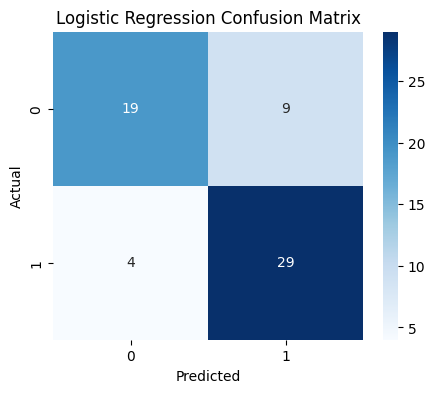

In [ ]:
#logistic regression matrix
cm_lr = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(5,4))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title('Logistic Regression Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

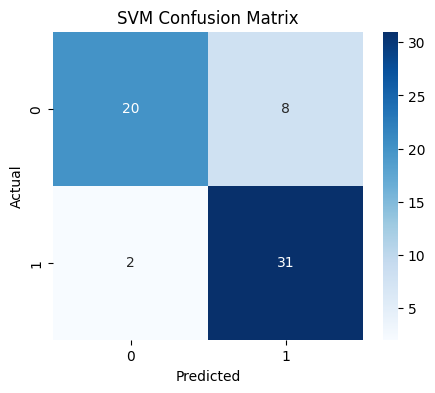

In [ ]:
#svm matric
cm_svm = confusion_matrix(y_test, y_pred_svm)

plt.figure(figsize=(5,4))

sns.heatmap(
    cm_svm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title('SVM Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

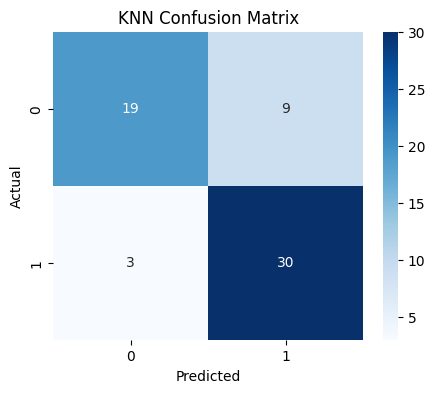

In [ ]:
#knn matrix
cm_knn = confusion_matrix(y_test, y_pred_knn)

plt.figure(figsize=(5,4))

sns.heatmap(
    cm_knn,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title('KNN Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

In [ ]:
#comparision table
results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'SVM',
        'KNN'
    ],

    'Accuracy': [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_svm),
        accuracy_score(y_test, y_pred_knn)
    ],

    'Precision': [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_svm),
        precision_score(y_test, y_pred_knn)
    ],

    'Recall': [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_svm),
        recall_score(y_test, y_pred_knn)
    ],

    'F1 Score': [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_svm),
        f1_score(y_test, y_pred_knn)
    ]
})

print(results)

                 Model  Accuracy  Precision    Recall  F1 Score
0  Logistic Regression  0.786885   0.763158  0.878788  0.816901
1                  SVM  0.836066   0.794872  0.939394  0.861111
2                  KNN  0.803279   0.769231  0.909091  0.833333


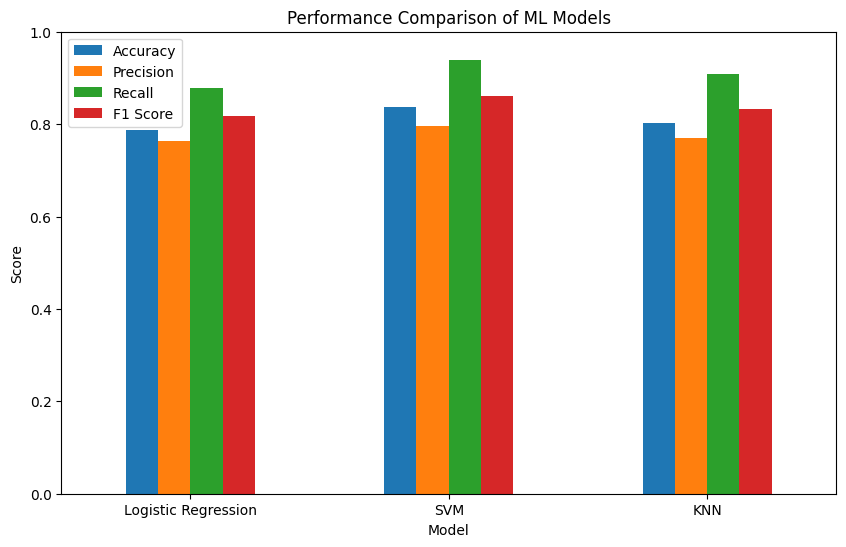

In [ ]:
#comparision graph
results.set_index('Model')[
    ['Accuracy', 'Precision', 'Recall', 'F1 Score']
].plot(
    kind='bar',
    figsize=(10,6)
)

plt.title('Performance Comparison of ML Models')
plt.xlabel('Model')
plt.ylabel('Score')
plt.ylim(0,1)

plt.xticks(rotation=0)

plt.show()

In [ ]:
# ============================================================
# FINAL HEART DISEASE PREDICTION SYSTEM
# USER ENTERS PATIENT DETAILS
# ============================================================

print("=" * 60)
print("       HEART DISEASE PREDICTION SYSTEM")
print("=" * 60)

print("\nPlease enter the patient's details.")
print("Use the values/coding used in the dataset.\n")


# ------------------------------------------------------------
# 1. GET INPUT FROM USER
# ------------------------------------------------------------

age = float(input("Enter Age: "))

sex = int(input("Enter Sex (0 = Female, 1 = Male): "))

cp = int(input("Enter Chest Pain Type (0-3): "))

trestbps = float(
    input("Enter Resting Blood Pressure: ")
)

chol = float(
    input("Enter Cholesterol: ")
)

fbs = int(
    input("Enter Fasting Blood Sugar (0 = No, 1 = Yes): ")
)

restecg = int(
    input("Enter Resting ECG Result (0-2): ")
)

thalach = float(
    input("Enter Maximum Heart Rate Achieved: ")
)

exang = int(
    input("Enter Exercise Induced Angina (0 = No, 1 = Yes): ")
)

oldpeak = float(
    input("Enter ST Depression (oldpeak): ")
)

slope = int(
    input("Enter Slope (0-2): ")
)

ca = int(
    input("Enter Number of Major Vessels (0-4): ")
)

thal = int(
    input("Enter Thalassemia Value (0-3): ")
)


# ------------------------------------------------------------
# 2. CREATE PATIENT DATA
# ------------------------------------------------------------

patient = [[
    age,
    sex,
    cp,
    trestbps,
    chol,
    fbs,
    restecg,
    thalach,
    exang,
    oldpeak,
    slope,
    ca,
    thal
]]


# ------------------------------------------------------------
# 3. SCALE THE NEW PATIENT DATA
# ------------------------------------------------------------

patient_scaled = scaler.transform(patient)


# ------------------------------------------------------------
# 4. PREDICTIONS FROM ALL THREE MODELS
# ------------------------------------------------------------

prediction_lr = logistic_model.predict(
    patient_scaled
)

prediction_svm = svm_model.predict(
    patient_scaled
)

prediction_knn = knn_model.predict(
    patient_scaled
)


# ------------------------------------------------------------
# 5. DISPLAY INDIVIDUAL MODEL PREDICTIONS
# ------------------------------------------------------------

print("\n")
print("=" * 60)
print("              PREDICTION RESULTS")
print("=" * 60)

print(
    "\nLogistic Regression:",
    "Heart Disease"
    if prediction_lr[0] == 1
    else "No Heart Disease"
)

print(
    "SVM:",
    "Heart Disease"
    if prediction_svm[0] == 1
    else "No Heart Disease"
)

print(
    "KNN:",
    "Heart Disease"
    if prediction_knn[0] == 1
    else "No Heart Disease"
)


# ------------------------------------------------------------
# 6. COUNT THE MODEL PREDICTIONS
# ------------------------------------------------------------

predictions = [
    prediction_lr[0],
    prediction_svm[0],
    prediction_knn[0]
]

heart_disease_count = predictions.count(1)
no_heart_disease_count = predictions.count(0)


# ------------------------------------------------------------
# 7. FINAL RESULT
# ------------------------------------------------------------

print("\n")
print("=" * 60)
print("                 FINAL RESULT")
print("=" * 60)

if heart_disease_count >= 2:

    print("\nResult: Heart Disease")

    print(
        f"{heart_disease_count} out of 3 models "
        "predicted the heart-disease class."
    )

else:

    print("\nResult: No Heart Disease")

    print(
        f"{no_heart_disease_count} out of 3 models "
        "predicted the no-heart-disease class."
    )


print("\n" + "=" * 60)
print("Prediction completed.")
print("=" * 60)

       HEART DISEASE PREDICTION SYSTEM

Please enter the patient's details.
Use the values/coding used in the dataset.

Enter Age: 55
Enter Sex (0 = Female, 1 = Male): 1
Enter Chest Pain Type (0-3): 1
Enter Resting Blood Pressure: 140
Enter Cholesterol: 250
Enter Fasting Blood Sugar (0 = No, 1 = Yes): 1
Enter Resting ECG Result (0-2): 2
Enter Maximum Heart Rate Achieved: 90
Enter Exercise Induced Angina (0 = No, 1 = Yes): 0
Enter ST Depression (oldpeak): 2
Enter Slope (0-2): 1
Enter Number of Major Vessels (0-4): 3
Enter Thalassemia Value (0-3): 2


              PREDICTION RESULTS

Logistic Regression: No Heart Disease
SVM: No Heart Disease
KNN: No Heart Disease


                 FINAL RESULT

Result: No Heart Disease
3 out of 3 models predicted the no-heart-disease class.

Prediction completed.


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
